In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [19]:
df = pd.read_csv('data/pima-indians-diabetes.data.csv')
df.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,2HPP,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [4]:
# جایگزینی مقدار های صفر با NaN
cols_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', '2HPP', 'BMI']
df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)

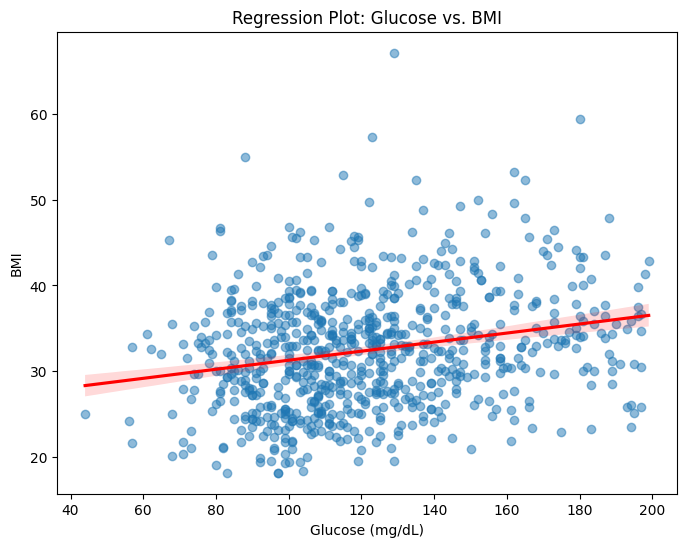

In [6]:
# 1. نسبت میزان رشد قند خون به BMI
plt.figure(figsize=(8, 6))
sns.regplot(x='Glucose', y='BMI', data=df, scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title('Regression Plot: Glucose vs. BMI')
plt.xlabel('Glucose (mg/dL)')
plt.ylabel('BMI')
plt.savefig('regression_plot.png')
plt.show()
plt.close()

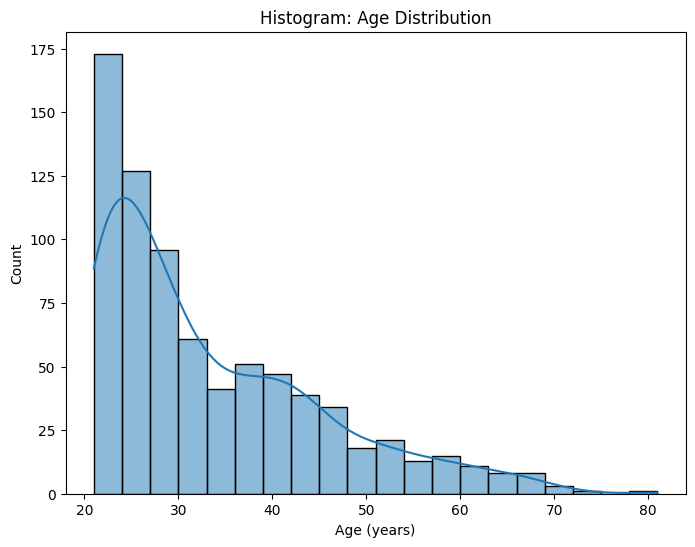

In [9]:
# 2. نمودار فراوانی سن
plt.figure(figsize=(8, 6))
sns.histplot(df['Age'], bins=20, kde=True)
plt.title('Histogram: Age Distribution')
plt.xlabel('Age (years)')
plt.ylabel('Count')
plt.savefig('histogram_plot.png')
plt.show()
plt.close()

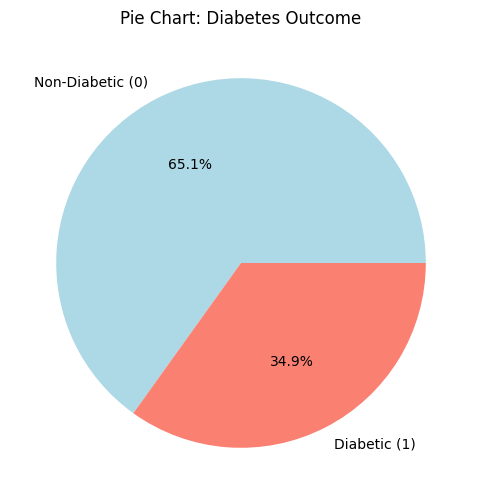

In [10]:
# 3. نسبت افراد با تست دیابت مثبت به منفی
outcome_counts = df['Outcome'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(outcome_counts, labels=['Non-Diabetic (0)', 'Diabetic (1)'], autopct='%1.1f%%', colors=['lightblue', 'salmon'])
plt.title('Pie Chart: Diabetes Outcome')
plt.savefig('pie_chart.png')
plt.show()
plt.close()

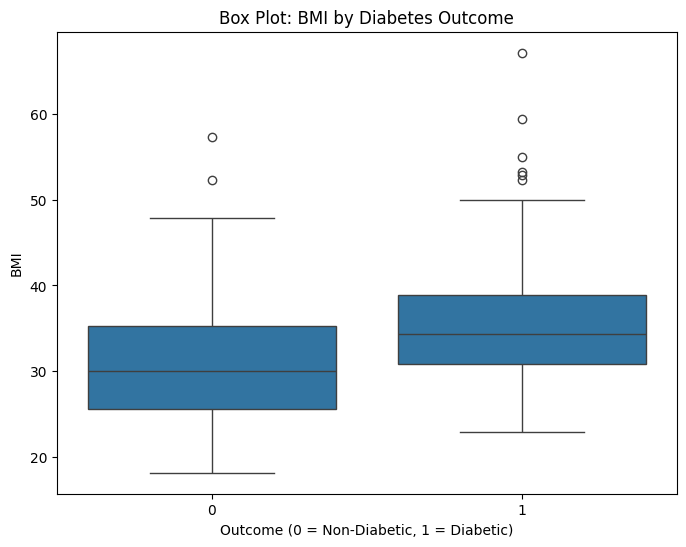

In [11]:
# 4. نسبت BMI به دیابت
plt.figure(figsize=(8, 6))
sns.boxplot(x='Outcome', y='BMI', data=df)
plt.title('Box Plot: BMI by Diabetes Outcome')
plt.xlabel('Outcome (0 = Non-Diabetic, 1 = Diabetic)')
plt.ylabel('BMI')
plt.savefig('box_plot.png')
plt.show()
plt.close()

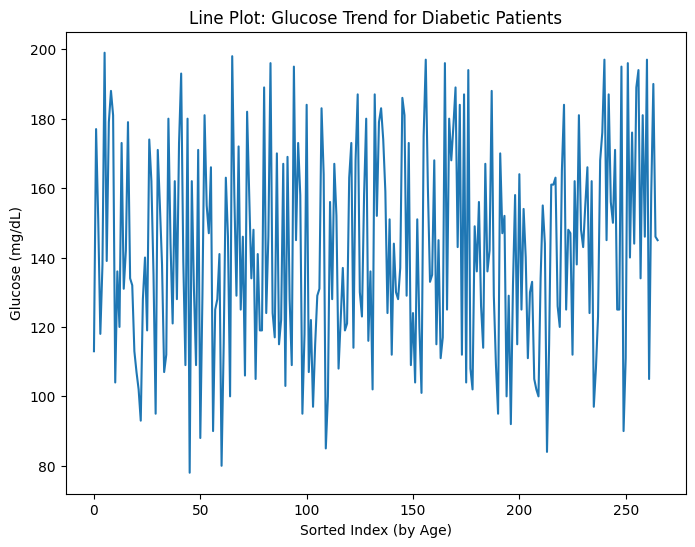

In [12]:
# 5. نسبت میزان قند خون به سن در بیماران با دیابت مثبت
diabetic_df = df[df['Outcome'] == 1][['Age', 'Glucose']].dropna().sort_values('Age')
plt.figure(figsize=(8, 6))
sns.lineplot(x=range(len(diabetic_df)), y='Glucose', data=diabetic_df)
plt.title('Line Plot: Glucose Trend for Diabetic Patients')
plt.xlabel('Sorted Index (by Age)')
plt.ylabel('Glucose (mg/dL)')
plt.savefig('line_plot.png')
plt.show()
plt.close()


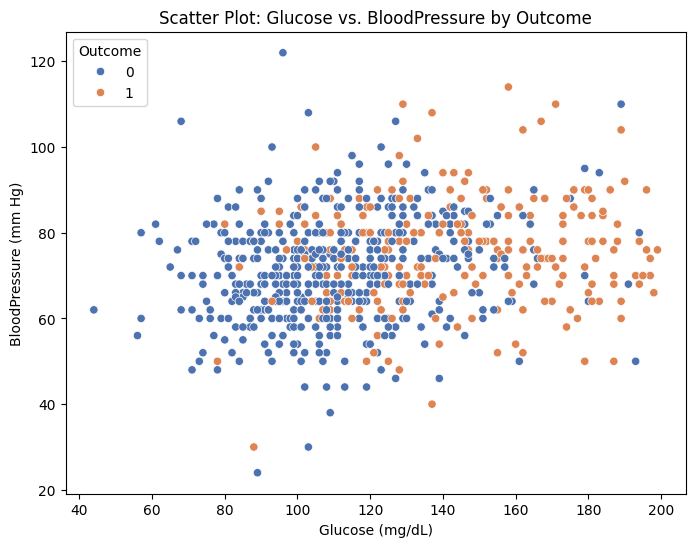

In [13]:
# 6. نسبت قند و فشار خون با نتیجه تست دیابت
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Glucose', y='BloodPressure', hue='Outcome', data=df, palette='deep')
plt.title('Scatter Plot: Glucose vs. BloodPressure by Outcome')
plt.xlabel('Glucose (mg/dL)')
plt.ylabel('BloodPressure (mm Hg)')
plt.savefig('scatter_plot.png')
plt.show()
plt.close()

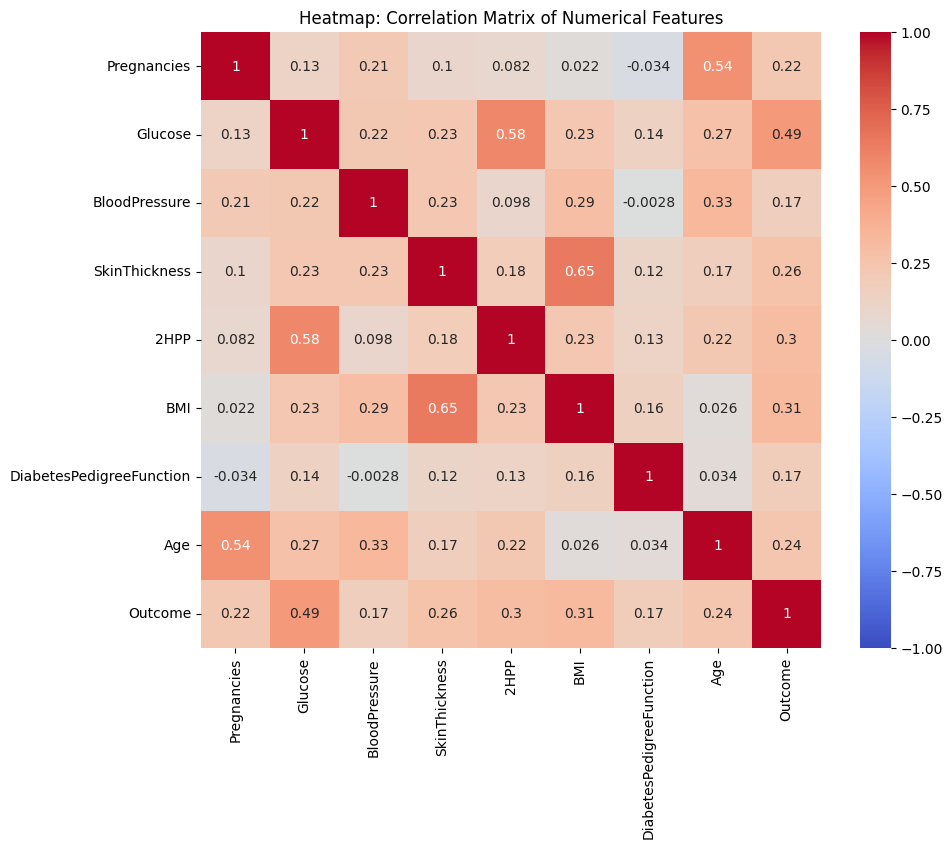

In [16]:
# 7. ماتریکس ارتباط داده ها
plt.figure(figsize=(10, 8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Heatmap: Correlation Matrix of Numerical Features')
plt.savefig('heatmap_plot.png')
plt.show()
plt.close()

<ipython-input-14-8d1dcbfbda10>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Outcome', data=df, palette='Set2')


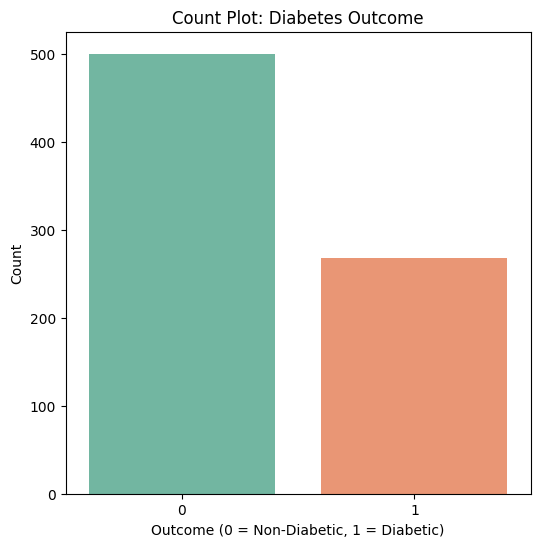

In [14]:
# 8. تعداد دیابتی ها در مقابل غیر دیابتی ها
plt.figure(figsize=(6, 6))
sns.countplot(x='Outcome', data=df, palette='Set2')
plt.title('Count Plot: Diabetes Outcome')
plt.xlabel('Outcome (0 = Non-Diabetic, 1 = Diabetic)')
plt.ylabel('Count')
plt.savefig('count_plot.png')
plt.show()
plt.close()